# WSCC 9 bus a trois technologies, avec un reseau de distribution CIGRE

Reseau de transport **WSCC 9 bus** dont les trois groupes sont de trois
technologies differentes : G1 reste une **machine synchrone** (slack), G2 devient
un onduleur **grid-forming** (`GFM1`, bus PV a 1,00 pu) et G3 un onduleur
**grid-following** (`GFL1`, bus PQ). Au bus de charge 5, un poste 230/110 kV
alimente un **reseau de distribution CIGRE MT** complet, avec ses deux departs,
ses charges et ses trois GFL (eolien et photovoltaique).

**Echelle de puissance.** Un reseau CIGRE porte 25,8 MW de charge, quand le bus 5
de la WSCC en consomme 125 MW. Le poste alimente donc `K = 4` reseaux CIGRE
identiques, agreges en un seul : toutes les puissances sont multipliees par `K`
et toutes les impedances divisees par `K`. Les tensions, les pertes relatives et
les dynamiques en pu sont exactement celles d'un seul reseau CIGRE, mais la
distribution porte 103 MW de charge et 11 MW de production. Le reste de la charge
du bus 5, 21,6 MW, demeure une charge agregee au facteur de puissance d'origine.

**Plan de tension.** La prise du poste 230/110 kV (`U2 = 1,025 x 110 kV`) remet
le 110 kV a 1,02 pu, la tension de la source amont du CIGRE d'origine ; les
transformateurs 110/20 kV restent sans prise. Le GFM tient 1,00 pu a son bus.
Le reseau de transport reste entre 1,01 et 1,04 pu, la MT entre 0,98 et 1,02 pu.

**Numerotation.** Tout ce qui appartient a la distribution porte un numero
superieur ou egal a 100 : bus 100 (110 kV) et 101 a 114 (20 kV), lignes,
transformateurs et GFL. Le poste 230/110 kV (transfo 100) en fait partie ; le
bus 5 est le poste de raccordement (PCC) cote transport. C'est cette convention
qu'utilise l'etude `python/etudes/transport_distribution.ipynb` pour separer
les deux reseaux.

```
  G1 (SM) --T1-- 1/4 ---- bus 6 ---- 9 --T3-- G3 (GFL)
                  |                  |
                bus 5 ---- bus 7 -- bus 8
                  |          |
          poste 230/110 kV  T2 -- G2 (GFM)
                  |
             bus 100 (110 kV)
             /             \
       T101 (110/20)    T102 (110/20)
            |                |
   depart 1 : bus 101-111   depart 2 : bus 112-114
   GFL eolien (107), PV (109)   GFL PV (113)
```

Base systeme : **100 MVA, 60 Hz**. Distribution : `K = 4` reseaux CIGRE agreges.

Equivalent MATLAB : `matlab/G2Elin_V2/reseaux_test/reseaux_classiques/WSCC_CIGRE.m`.

### Comment comparer avec MATLAB

| Notebook (Python) | MATLAB |
|---|---|
| `net.run_loadflow()` | `net.Load_flow(Y_DER, false)` |
| `net.build_state_space()` | `net.buildGlobalModel()` |
| tableau modal ci-dessous | `displayModalAnalysis()` (`EigenVal_Table = 1`) |

Le tableau modal reprend les conventions MATLAB : participation
`p_ki = |v_gauche . v_droit|` normalisee par mode, `f_undamp = |lambda|/2pi`,
`f_damp = |Im(lambda)|/2pi`, `zeta = -Re(lambda)/|lambda|`, tri par
`Re(lambda)` decroissant, tous les modes conjugues inclus.

In [1]:
import sys
import pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import plotly.graph_objects as go


# Le paquet g2egrid est a la racine du projet (dossier parent de reseaux_test/).
ROOT = pathlib.Path.cwd()
ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from g2egrid import Network  # noqa: E402
from g2egrid.elements import (  # noqa: E402
    GFL1,
    GFL2,
    GFM1,
    GFM2,
    GFM3,
    GFM4,
    IB,
    Bus,
    ILoad,
    Line,
    PLoad,
    RLLoad,
    SynchronousMachine,
    SynchronousMachineTR,
    Transformer,
)

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)

## 1. Construction du reseau

### 1.1 Donnees et assemblage

In [2]:
NOM_RESEAU = "WSCC9_CIGRE"
F_ZOOM = 5.0

f0 = 60.0
Sb = 100e6
# reseau de parite MATLAB : les noeuds sans capacite gardent la resistance
# de causalite de Node.m (setResistor(100)) ; le defaut de g2egrid est le
# noeud ideal (FR-005)
NOEUDS = "resistance"

# --- Distribution : K reseaux CIGRE MT identiques derriere le poste 230/110 kV
#     du bus 5. Agreger K reseaux identiques revient a multiplier les puissances
#     par K et a diviser les impedances par K : tensions, pertes relatives et
#     dynamiques en pu restent celles d'un seul reseau CIGRE.
K = 4
TAP_HT = 1.025   # prise du poste 230/110 kV : 110 kV a 1,03 pu, comme la source CIGRE
TAP_MT = 1.000   # transfos 110/20 kV du CIGRE, sans prise

# --- Bus 5 : 125 MW / 50 Mvar dans la WSCC. La distribution en porte
#     K x 25,84 MW ; le reste demeure une charge agregee, au facteur de
#     puissance de la charge d'origine.
P5 = 125e6 - K * 25.84e6
Q5 = 50e6 * P5 / 125e6

# BusType : 1 = slack, 2 = PV, 3 = PQ

Y_DER = [ # [BusID, BusType, V_base, V_pu, Theta_rad,     Pg_W, Qg_var,          Pl_W,        Ql_var]
        (    1,       1,     16.5e3, 1.040,        0,        0,      0,             0,             0),  # G1 : SM (slack)
        (    2,       2,     18.0e3, 1.000,        0,    163e6,      0,             0,             0),  # G2 : GFM
        (    3,       3,     13.8e3, 1.000,        0,     85e6,      0,             0,             0),  # G3 : GFL
        (    4,       3,      230e3, 1.000,        0,        0,      0,             0,             0),
        (    5,       3,      230e3, 1.000,        0,        0,      0,            P5,            Q5),  # PCC
        (    6,       3,      230e3, 1.000,        0,        0,      0,          90e6,          30e6),
        (    7,       3,      230e3, 1.000,        0,        0,      0,             0,             0),
        (    8,       3,      230e3, 1.000,        0,        0,      0,         100e6,          35e6),
        (    9,       3,      230e3, 1.000,        0,        0,      0,             0,             0),
        (  100,       3,      110e3, 1.000,        0,        0,      0,             0,             0),  # poste 110 kV
        (  101,       3,       20e3, 1.000,        0,        0,      0,   K * 20.4e6,     K * 1e6),
        (  102,       3,       20e3, 1.000,        0,        0,      0,             0,             0),
        (  103,       3,       20e3, 1.000,        0,        0,      0,    K * 550e3,    K * 50e3),
        (  104,       3,       20e3, 1.000,        0,        0,      0,    K * 445e3,    K * 50e3),
        (  105,       3,       20e3, 1.000,        0,        0,      0,    K * 750e3,    K * 50e3),
        (  106,       3,       20e3, 1.000,        0,        0,      0,    K * 565e3,    K * 50e3),
        (  107,       3,       20e3, 1.000,        0, K * 1.2e6,     0,     K * 90e3,    K * 50e3),
        (  108,       3,       20e3, 1.000,        0,        0,      0,    K * 605e3,    K * 50e3),
        (  109,       3,       20e3, 1.000,        0, K * 0.8e6,     0,    K * 675e3,    K * 50e3),
        (  110,       3,       20e3, 1.000,        0,        0,      0,    K * 570e3,    K * 50e3),
        (  111,       3,       20e3, 1.000,        0,        0,      0,    K * 340e3,    K * 50e3),
        (  112,       3,       20e3, 1.000,        0,        0,      0,    K * 205e3,    K * 50e3),
        (  113,       3,       20e3, 1.000,        0, K * 0.8e6,     0,     K * 40e3,    K * 50e3),
        (  114,       3,       20e3, 1.000,        0,        0,      0,    K * 605e3,    K * 50e3),
]

T_Lines_SI = [
# T_Lines_SI : [ID, From, To, Length_km, R_ohm/km,   X_ohm/km,        B_S/km]   (CIGRE / K)
              (101,  101, 102,     2.82, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (102,  102, 103,     4.42, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (103,  103, 104,     0.61, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (104,  104, 105,     0.56, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (105,  105, 106,     1.54, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (106,  107, 108,     1.67, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (107,  108, 109,     0.32, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (108,  109, 110,     0.77, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (109,  110, 111,     0.33, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (110,  103, 108,     1.30, 0.501 / K, 0.716 / K, 47.493e-6 * K),
              (111,  112, 113,     4.89, 0.510 / K, 0.366 / K,  3.172e-6 * K),
              (112,  113, 114,     2.99, 0.510 / K, 0.366 / K,  3.172e-6 * K),
]

T_Lines_pu = [
# T_Lines_pu : [ID, From, To, Length_km,   R_pu,   X_pu,   B_pu,  Un_V, Sb_VA]   (WSCC)
              (  1,    4,  5,         1, 0.0100, 0.0850, 0.1760, 230e3, 100e6),
              (  2,    4,  6,         1, 0.0170, 0.0920, 0.1580, 230e3, 100e6),
              (  3,    5,  7,         1, 0.0320, 0.1610, 0.3060, 230e3, 100e6),
              (  4,    6,  9,         1, 0.0390, 0.1700, 0.3580, 230e3, 100e6),
              (  5,    7,  8,         1, 0.0085, 0.0720, 0.1490, 230e3, 100e6),
              (  6,    8,  9,         1, 0.0119, 0.1008, 0.2090, 230e3, 100e6),
]

# T_Shunts : [ID, BusID, B_pu]   (compensation shunt propre au bus)
T_Shunts = []

#   Une prise hors nominal se declare par U1_V/U2_V (comme Network.m)
T_Transfos = [
 # T_Transfos : [ID, From, To,       Sn_VA,   U1_V,           U2_V,   R_pu,   X_pu]
               (  1,    1,   4,       100e6, 16.5e3,          230e3,      0, 0.0576),  # G1
               (  2,    2,   7,       100e6, 18.0e3,          230e3,      0, 0.0625),  # G2
               (  3,    3,   9,       100e6, 13.8e3,          230e3,      0, 0.0586),  # G3
               (100,    5, 100,  K * 50e6,  230e3, TAP_HT * 110e3,  0.003,   0.12),  # poste 230/110 kV
               (101,  100, 101,  K * 25e6,  110e3,  TAP_MT * 20e3, 0.0016,   0.12),  # CIGRE, depart 1
               (102,  100, 112,  K * 25e6,  110e3,  TAP_MT * 20e3, 0.0016,   0.12),  # CIGRE, depart 2
]

# T_IBs : [ID, BusID, Sn_VA, E_pu, theta_deg, R_pu, X_pu]
T_IBs = []

# T_SMs : [ID, BusID, Sn_VA]
T_SMs = [
    (  1,  1, 247.5e6),
]
SM_PARAMS = {}

# T_GFM1s a T_GFM4s : [ID, BusID, Sn_VA, Vdc_V]
T_GFM1s = [
    (  1,  2, 200e6, 40e3),
]
T_GFM2s = []
T_GFM3s = []
T_GFM4s = []
GFM_PARAMS = {}

# T_GFL1s : [ID, BusID, Sn_VA, Vdc_V]
T_GFL1s = [
    (  1,   3,       130e6, 40e3),      # G3 : GFL de transport
    (101, 107, K * 1.5e6, 40e3),        # CIGRE : eolien
    (102, 109, K * 1.0e6, 40e3),        # CIGRE : PV
    (103, 113, K * 1.0e6, 40e3),        # CIGRE : PV
]
T_GFL2s = []
GFL_PARAMS = {}

# T_Loads : [ID, BusID, P_W, Q_var, Type]   (charges SPECIALES)
#   Type : 'I' = courant constant, 'P' = puissance constante. Les charges
#   classiques (R-L) viennent des colonnes Pl_W, Ql_var de Y_DER.
T_Loads = []

In [3]:
# --- bases de tension par bus, lues dans Y_DER ---
UN = {int(r[0]): r[2] for r in Y_DER}

# --- capacite shunt de chaque bus : moitie de la charge des lignes qui y
#     aboutissent (schema en pi), comme C_half = B_pu/2 dans Network.m. Un bus
#     qui n'en recoit aucune devient un noeud ALGEBRIQUE a resistance de
#     causalite R = 100 pu (Node.m / setResistor(100)). ---
Cbus = {int(r[0]): 0.0 for r in Y_DER}
for _id, i, j, km, _r, _x, b_km in T_Lines_SI:
    b_pu = b_km * km * (UN[i] ** 2 / Sb)
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
for _id, i, j, _km, _r, _x, b_pu, Un, Sb_l in T_Lines_pu:
    b_pu = b_pu * (UN[i] ** 2 / Sb) / (Un ** 2 / Sb_l)  # base de la ligne -> base systeme
    Cbus[i] += b_pu / 2.0
    Cbus[j] += b_pu / 2.0
# compensation shunt propre a un bus (banc de condensateurs), qui s'ajoute a
# la charge capacitive des lignes. MATLAB n'a pas de colonne pour cela dans
# Y_DER : d'ou une table a part, plutot qu'une colonne en plus.
for _id, b, B_pu in T_Shunts:
    Cbus[b] += B_pu

# --- charges speciales de T_Loads : leur consommation s'ajoute a celle de
#     Y_DER dans le load flow ---
CHARGES_SPECIALES = {"I": ILoad, "P": PLoad}
S_spec = {int(r[0]): [0.0, 0.0] for r in Y_DER}
for _id, b, P, Q, typ in T_Loads:
    if typ not in CHARGES_SPECIALES:
        raise ValueError(f"T_Loads, charge {_id} : type '{typ}' inconnu ('I' ou 'P')")
    S_spec[b][0] += P
    S_spec[b][1] += Q

# --- assemblage du reseau
net = Network(f0=f0, Sb=Sb, noeuds_sans_capacite=NOEUDS)

for bid, btype, Un, Vpu, theta, Pg, Qg, Pl, Ql in Y_DER:  # Y_DER
    net.add(
        Bus(
            int(bid),
            Un,
            btype=int(btype),
            V=Vpu,
            theta=theta,
            Pg=Pg,
            Qg=Qg,
            Pl=Pl + S_spec[int(bid)][0],
            Ql=Ql + S_spec[int(bid)][1],
            C=Cbus[int(bid)],
        )
    )

for lid, i, j, km, r_km, x_km, _b in T_Lines_SI:  # T_Lines_SI
    ZB = UN[i] ** 2 / Sb
    net.add(
        Line(
            f"L{int(lid)}_{i}_{j}", i, j, R=r_km * km / ZB, X=x_km * km / ZB, wb=net.wb
        )
    )

for lid, i, j, _km, r_pu, x_pu, _b, Un, Sb_l in T_Lines_pu:  # T_Lines_pu
    k = (Un ** 2 / Sb_l) / (UN[i] ** 2 / Sb)  # base de la ligne -> base systeme
    net.add(Line(f"L{int(lid)}_{i}_{j}", i, j, R=r_pu * k, X=x_pu * k, wb=net.wb))

# Une prise hors nominal se declare par U1_V/U2_V, comme dans Network.m :
# n = (U1/U2)/(Un_i/Un_j), egal a 1 quand U1, U2 sont les tensions des bus.
for tid, i, j, Sn, U1, U2, R, X in T_Transfos:  # T_Transfos
    k = (Sb / Sn) * (U1 / UN[i]) ** 2  # base du transfo -> base systeme
    n = (U1 / U2) / (UN[i] / UN[j])
    net.add(Transformer(f"T{int(tid)}_{i}_{j}", i, j, R=R * k, X=X * k, wb=net.wb, n=n))

for _id, b, Sn, _E, _th, R, X in T_IBs:  # T_IBs
    net.add(IB(f"IB{b}", b, R=R, X=X, wb=net.wb, Sn=Sn, Sb=Sb))

# Colonnes optionnelles Rt_pu, Xt_pu des tables de DER : transfo de
# raccordement INTEGRE a l'equipement. Sans elles, la machine n'a pas de
# transfo (a declarer dans T_Transfos) et le convertisseur garde son filtre
# R2/L2 par defaut.
for _id, b, Sn, *Tr in T_SMs:  # T_SMs
    if Tr:
        net.add(SynchronousMachineTR(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, Rt=Tr[0], Lt=Tr[1], **SM_PARAMS))
    else:
        net.add(SynchronousMachine(f"SM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **SM_PARAMS))

for T_GFM, GFM in ((T_GFM1s, GFM1), (T_GFM2s, GFM2), (T_GFM3s, GFM3), (T_GFM4s, GFM4)):  # T_GFM1s a T_GFM4s
    for _id, b, Sn, _Vdc, *Tr in T_GFM:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFM(f"GFM{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFM_PARAMS | tr)))

for T_GFL, GFL in ((T_GFL1s, GFL1), (T_GFL2s, GFL2)):  # T_GFL1s, T_GFL2s
    for _id, b, Sn, _Vdc, *Tr in T_GFL:
        tr = dict(R2_pu=Tr[0], L2_pu=Tr[1]) if Tr else {}
        net.add(GFL(f"GFL{b}", b, Sn=Sn, Sb=Sb, wb=net.wb, **(GFL_PARAMS | tr)))

# Charges classiques : colonnes Pl_W, Ql_var de Y_DER -> charge R-L a
# impedance constante (GenericLoad.m). Une inductance ne peut pas consommer
# un reactif negatif ou nul : condensateur dans T_Shunts, ou charge speciale.
n_rl = 0
for bid, *_, Pl, Ql in Y_DER:  # Y_DER : charges classiques
    if Pl == 0 and Ql == 0:
        continue
    if Ql <= 0:
        raise ValueError(
            f"bus {int(bid)} : Ql = {Ql:g} var. Une charge R-L demande Ql > 0 ; "
            "declarer le condensateur dans T_Shunts ou la charge dans T_Loads ('P' ou 'I')"
        )
    net.add(RLLoad(f"Load{int(bid)}", int(bid), P=Pl / Sb, Q=Ql / Sb, wb=net.wb))
    n_rl += 1

for lid, b, P, Q, typ in T_Loads:  # T_Loads : charges speciales
    net.add(CHARGES_SPECIALES[typ](f"Load{typ}{int(lid)}_{b}", b, P=P / Sb, Q=Q / Sb))

n_gfm = len(T_GFM1s) + len(T_GFM2s) + len(T_GFM3s) + len(T_GFM4s)
print(
    f"{NOM_RESEAU} : {len(Y_DER)} bus, "
    f"{len(T_Lines_SI) + len(T_Lines_pu)} ligne(s), {len(T_Transfos)} transfo(s), "
    f"{len(T_IBs)} bus infini, {len(T_SMs)} machine(s), {n_gfm} GFM, "
    f"{len(T_GFL1s) + len(T_GFL2s)} GFL, {n_rl} charge(s) R-L, "
    f"{len(T_Loads)} charge(s) speciale(s)"
)

WSCC9_CIGRE : 24 bus, 18 ligne(s), 6 transfo(s), 0 bus infini, 1 machine(s), 1 GFM, 4 GFL, 16 charge(s) R-L, 0 charge(s) speciale(s)


### 1.2 Load flow

In [4]:
lf = net.run_loadflow()
print(
    f"Load flow : converge en {lf.iterations} iterations (mismatch {lf.mismatch:.2e})\n"
)

print(
    f"{'bus':>4} {'|V| [pu]':>10} {'angle [deg]':>12} "
    f"{'P inj [pu]':>12} {'Q inj [pu]':>12}"
)
print("-" * 54)
for b, i in net._bus_index().items():
    print(
        f"{b:>4} {abs(lf.V[i]):>10.4f} {np.degrees(np.angle(lf.V[i])):>12.4f} "
        f"{lf.S[i].real:>12.4f} {lf.S[i].imag:>12.4f}"
    )
print(
    f"\nSomme des injections : P = {lf.S.real.sum():+.4f} pu, "
    f"Q = {lf.S.imag.sum():+.4f} pu  (= pertes)"
)

Load flow : converge en 5 iterations (mismatch 1.88e-11)

 bus   |V| [pu]  angle [deg]   P inj [pu]   Q inj [pu]
------------------------------------------------------
   1     1.0400       0.0000       0.6507       0.1706
   2     1.0000      10.0041       1.6300      -0.1664
   3     1.0386       4.8197       0.8500       0.0000
   4     1.0312      -1.9696      -0.0000       0.0000
   5     1.0084      -3.4208      -0.2164      -0.0866
   6     1.0190      -3.4058      -0.9000      -0.3000
   7     1.0155       4.2817       0.0000       0.0000
   8     1.0128       1.1341      -1.0000      -0.3500
   9     1.0397       2.2094      -0.0000       0.0000
 100     1.0215      -6.4583       0.0000       0.0000
 101     1.0080     -12.6260      -0.8160      -0.0400
 102     0.9971     -13.3286      -0.0000       0.0000
 103     0.9799     -14.4393      -0.0220      -0.0020
 104     0.9784     -14.5493      -0.0178      -0.0020
 105     0.9774     -14.6254      -0.0300      -0.0020
 106   

## 2. Modele d'etat

Equilibre element par element (Newton sur `[f; g] = 0`), puis assemblage
global : cablage des ports par LFT, elimination des variables algebriques
par complement de Schur.

In [5]:
net.solve_equilibrium()
ss = net.build_state_space()

print(ss)
print(f"\n{len(ss.states)} etats, {len(ss.inputs)} entrees, {len(ss.outputs)} sorties")
print(f"stable : {ss.is_stable()}   max Re(lambda) = {ss.eig().real.max():+.4e}")

print("\nEtats par element :")
seen = []
for s in ss.states:
    owner = s.split(".")[0]
    if owner not in seen:
        seen.append(owner)
for owner in seen:
    noms = [s.split(".", 1)[1] for s in ss.states if s.startswith(owner + ".")]
    print(f"  {owner:<12} {len(noms):>3} : {', '.join(noms)}")

<StateSpace 230 etats, 46 entrees, 187 sorties | max Re(lambda)=-4.670e-12>

230 etats, 46 entrees, 187 sorties
stable : True   max Re(lambda) = -4.6698e-12

Etats par element :
  bus4           2 : vd, vq
  bus5           2 : vd, vq
  bus6           2 : vd, vq
  bus7           2 : vd, vq
  bus8           2 : vd, vq
  bus9           2 : vd, vq
  bus101         2 : vd, vq
  bus102         2 : vd, vq
  bus103         2 : vd, vq
  bus104         2 : vd, vq
  bus105         2 : vd, vq
  bus106         2 : vd, vq
  bus107         2 : vd, vq
  bus108         2 : vd, vq
  bus109         2 : vd, vq
  bus110         2 : vd, vq
  bus111         2 : vd, vq
  bus112         2 : vd, vq
  bus113         2 : vd, vq
  bus114         2 : vd, vq
  L101_101_102   2 : i_d, i_q
  L102_102_103   2 : i_d, i_q
  L103_103_104   2 : i_d, i_q
  L104_104_105   2 : i_d, i_q
  L105_105_106   2 : i_d, i_q
  L106_107_108   2 : i_d, i_q
  L107_108_109   2 : i_d, i_q
  L108_109_110   2 : i_d, i_q
  L109_110_111   2 : i

### 2.1 Tableau modal

Une ligne par valeur propre, triee par partie reelle decroissante (modes les
plus lents d'abord), comme `displayModalAnalysis` en MATLAB : une paire
conjuguee occupe deux lignes. L'index `Mode` est l'indice `k` de `lam[k]`.

| Colonne | Definition |
|---|---|
| `Re`, `Im` | parties reelle [1/s] et imaginaire [rad/s] de la valeur propre |
| `f_und [Hz]` | frequence propre non amortie, `abs(lambda) / 2pi` |
| `f_dam [Hz]` | frequence d'oscillation, `abs(Im) / 2pi` |
| `zeta [%]` | amortissement, `-Re / abs(lambda)` |
| `Etat j`, `%j` | j-ieme etat le plus participant et sa participation `abs(v_ki . w_ik)`, normalisee a 100 % par mode |

In [6]:
lam, Vr = np.linalg.eig(ss.A)
Wl = np.linalg.inv(Vr)
Pf = np.abs(Vr.T) * np.abs(Wl)  # Pf[k, i] : participation de l'etat i au mode k
Pf = Pf / np.maximum(Pf.sum(axis=1, keepdims=True), 1e-30)
top3 = np.argsort(-Pf, axis=1)[:, :3]  # les trois etats les plus participants
k = np.arange(len(lam))

mag = np.abs(lam)
zeta = np.where(mag > 1e-10, -lam.real / np.where(mag > 1e-10, mag, 1.0), 0.0)

T_eig = pd.DataFrame(
    {
        "Re": lam.real,
        "Im": lam.imag,
        "f_und [Hz]": mag / (2 * np.pi),
        "f_dam [Hz]": np.abs(lam.imag) / (2 * np.pi),
        "zeta [%]": 100 * zeta,
    }
)
for j in range(3):
    T_eig[f"Etat {j + 1}"] = [ss.states[i] for i in top3[:, j]]
    T_eig[f"%{j + 1}"] = 100 * Pf[k, top3[:, j]]
T_eig = T_eig.iloc[np.argsort(-lam.real, kind="stable")]
T_eig.index.name = "Mode"



T_eig

,Re,Im,f_und [Hz],f_dam [Hz],zeta [%],Etat 1,%1,Etat 2,%2,Etat 3,%3
Mode,,,,,,,,,,,
176,1.201623e-11,0.000000,1.912443e-12,0.000000,0.000000,GFM2.theta,80.608061,SM1.theta,19.391843,GFL3.theta_pll,0.000072
187,-1.846009e-01,0.000000,2.938014e-02,0.000000,100.000000,SM1.vpss,98.005259,GFM2.theta,0.772052,SM1.v2,0.383882
186,-5.152407e-01,0.000000,8.200310e-02,0.000000,100.000000,SM1.v1,74.274792,SM1.v2,6.240928,SM1.theta,5.301741
185,-6.052802e-01,0.000000,9.633333e-02,0.000000,100.000000,SM1.theta,24.885766,SM1.phi_1q,24.511379,SM1.v1,18.407424
174,-1.911508e+00,12.251660,1.973502e+00,1.949912,15.415536,SM1.Dwr,32.620432,SM1.Pm,20.433495,SM1.theta,8.343618
...,...,...,...,...,...,...,...,...,...,...,...
5,-1.254539e+06,-376.991118,1.996660e+05,60.000000,99.999995,T100_5_100.i_d,25.041720,T100_5_100.i_q,25.041720,T101_100_101.i_d,12.503403
2,-5.544293e+06,376.991118,8.824017e+05,60.000000,100.000000,GFL3.igq,44.198193,GFL3.igd,44.198193,T3_3_9.i_d,5.801619
3,-5.544293e+06,-376.991118,8.824017e+05,60.000000,100.000000,GFL3.igq,44.198193,GFL3.igd,44.198193,T3_3_9.i_d,5.801619


### 2.2 Carte des valeurs propres

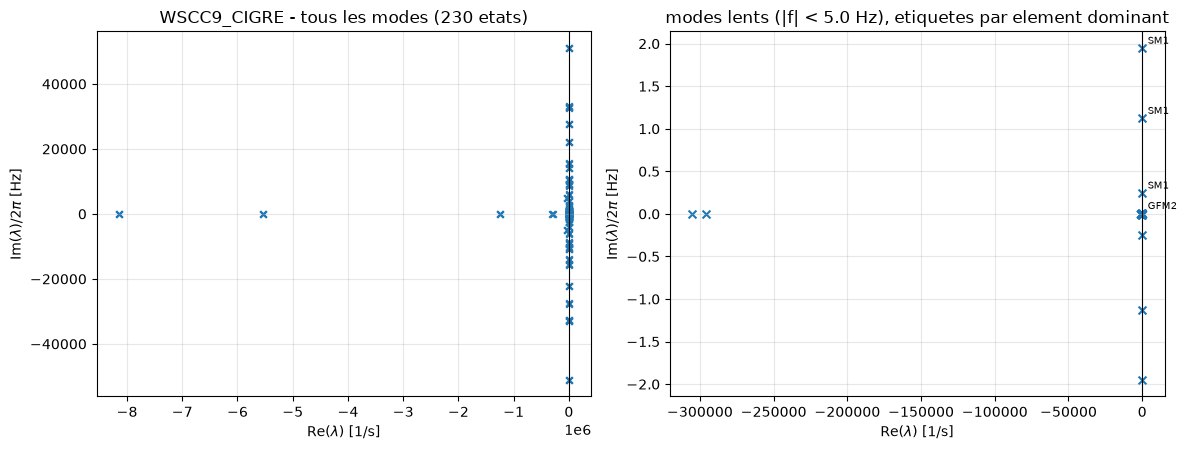

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))

ax[0].scatter(lam.real, lam.imag / (2 * np.pi), s=22, marker="x")
ax[0].axvline(0.0, color="k", lw=0.8)
ax[0].set_xlabel("Re($\\lambda$) [1/s]")
ax[0].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[0].set_title(f"{NOM_RESEAU} - tous les modes ({len(lam)} etats)")
ax[0].grid(True, alpha=0.3)

zoom = np.abs(lam.imag) / (2 * np.pi) <= F_ZOOM
ax[1].scatter(lam[zoom].real, lam[zoom].imag / (2 * np.pi), s=32, marker="x")
for k in np.flatnonzero(zoom & (lam.imag > 1e-6)):
    ax[1].annotate(
        ss.states[top3[k, 0]].split(".")[0],
        (lam[k].real, lam[k].imag / (2 * np.pi)),
        fontsize=7,
        xytext=(4, 3),
        textcoords="offset points",
    )
ax[1].axvline(0.0, color="k", lw=0.8)
ax[1].set_xlabel("Re($\\lambda$) [1/s]")
ax[1].set_ylabel("Im($\\lambda$)/2$\\pi$ [Hz]")
ax[1].set_title(f"modes lents (|f| < {F_ZOOM} Hz), etiquetes par element dominant")
ax[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
fig = go.Figure()

fig.add_trace(go.Scatter(x=T_eig["Re"], y=T_eig["Im"], mode="markers"))

fig.update_xaxes(range=[-1000, 10])
fig.update_yaxes(range=[-10, 1000])
fig.show()